In [70]:
import os
os.environ['KERAS_BACKEND'] = 'jax'
import keras
import tensorflow as tf

import pickle
import time
import bayesflow as bf

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from functions.prior import prior
from functions.likelihood import likelihood
from constants import SHAPE_PRIOR_RANGES, FLASH_PAIRS, CUE, HAS_DEADLINE, MODEL_NAMES
from functions.resimulate_from_posterior import resimulate_from_posterior


In [4]:
simulator = bf.make_simulator([prior, likelihood])

sim_draws = simulator.sample(50)

In [5]:
par_keys = [
    "a_base",
    "v_scale",
    "t0",
    
]
par_names = [r"$a_\text{base}$", r"$v_\text{scale}$", r"$t_0$",]

In [16]:
# f = bf.diagnostics.plots.pairs_samples(
#     samples=sim_draws,
#     variable_keys=par_keys,
#     variable_names=par_names
# )

In [6]:
# 4 Parameter: v_scale, t0, a, lam
num_params = 4

inference_network = bf.networks.CouplingFlow(
    num_params=num_params,
    num_coupling_layers=4,
    coupling_design="interleaved"
)

In [7]:
@keras.saving.register_keras_serializable()
def stack_trials_for_deepset(data, **kwargs):
    # if required keys are not present: return data as is
    # handle cases where data is already processed or in inverse mode
    if 'rt' not in data or 'choice' not in data or 'coherence' not in data:
        return data

    # stack rt, choice, and coherence along a new axis to create 2D array
    # Each row is one trial, and columns are features (rt, choice, coherence)
    stacked_data = tf.stack([data['rt'], data['choice'], data['coherence']], axis=-1)

    # new dictionary from input data
    # and adding 'summary_variables'
    output_data = {k: v for k, v in data.items() if k not in ['rt', 'choice', 'coherence']}
    output_data['summary_variables'] = stacked_data
    return output_data

adapter = (
    bf.adapters.Adapter()
    .to_array()
    .convert_dtype("float64", "float32")
    .concatenate(["v_scale", "t0", "a_base","lam"], into="inference_variables")
    .add_transform(stack_trials_for_deepset)
    .keep(["inference_variables", "summary_variables"])
)

In [8]:
 # coherence is present in the summary variables, so its going in the network.
sample = simulator.sample(batch_shape=(4,))
adapted = adapter(sample)
sv = adapted["summary_variables"]
print(sv.shape)                     
print(np.unique(sv[0, :, 2]))       

(4, 360, 3)
[0.1 0.2 0.3 0.4 0.5 0.6]


In [12]:

CHECKPOINT_DIR = os.path.join("models", "checkpoints", "ddm_sbi_run")
os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs("./models/networks", exist_ok=True) 

print(CHECKPOINT_DIR)

workflow = bf.BasicWorkflow(
    simulator=simulator,
    adapter=adapter,
    inference_network=inference_network,
    summary_network=bf.networks.SetTransformer(),
    checkpoint_filepath=CHECKPOINT_DIR,
    checkpoint_name="ddm_workflow",
)


Existing checkpoints are not automatically loaded. Upon refitting, the checkpoints will be overwritten.
To load the stored approximator from the checkpoint, use approximator = keras.saving.load_model("models\checkpoints\ddm_sbi_run/ddm_workflow.keras")


models\checkpoints\ddm_sbi_run


In [10]:
## TRAINING THE MODEL
# commented out because of runtime

EPOCHS, BATCH_SIZE, NUM_BATCHES = 30, 400, 64

# history = workflow.fit_online(epochs=EPOCHS, batch_size=BATCH_SIZE, num_batches_per_epoch=NUM_BATCHES)

history_path = f"./models/networks/bayesflow_history_epoch_{EPOCHS}.pkl"
# tmp_path = history_path + ".tmp"
# with open(tmp_path, "wb") as f:
#     pickle.dump(history, f)
# os.replace(tmp_path, history_path)

# print(f"History saved successfully to {history_path}!")
# print(f"Model weights were checkpointed automatically to {CHECKPOINT_DIR}/")


In [13]:
if os.path.exists(history_path) and os.path.getsize(history_path) > 0:
    with open(history_path, "rb") as f:
        history = pickle.load(f)
else:
    raise FileNotFoundError(
        f"{history_path} is missing or empty - re-run the training cell above "
        "before continuing."
    )


approximator = keras.saving.load_model(os.path.join(CHECKPOINT_DIR, "ddm_workflow.keras"))


## **Diagnostics**

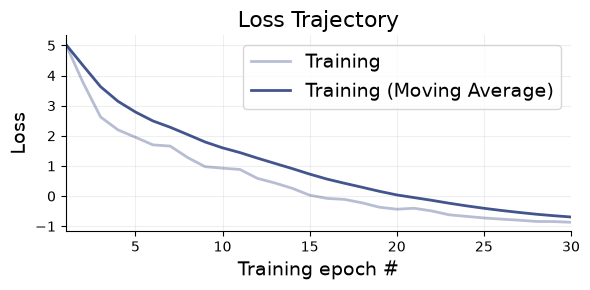

In [ ]:
# Convergence
f  = bf.diagnostics.loss(history, figsize=(6,3))

Sampling: 100%|██████████| 1/1 [00:05<00:00,  5.13s/batch]
INFO:bayesflow:Sampling completed in 10.99 seconds.


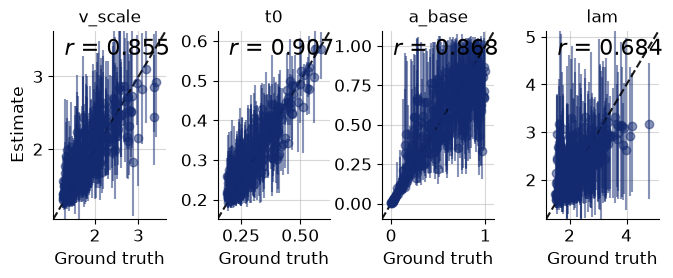

In [ ]:
# SB calibration
workflow.approximator = approximator

# recovery rates

num_samples = 1000
test_sims = workflow.simulate(300)
test_sims_params = {k: v for k, v in test_sims.items() if k in par_keys}
test_sims_data = {k: v for k, v in test_sims.items() if k not in par_keys}

samples = workflow.sample(conditions=test_sims_data, num_samples=num_samples)



In [27]:
# settings for plots
label_map = {
    "v_scale": r"$v_{scale}$",
    "t0": r"$t_0$",
    "a_base": r"$a_{base}$",
    "lam": r"$\lambda$",
}

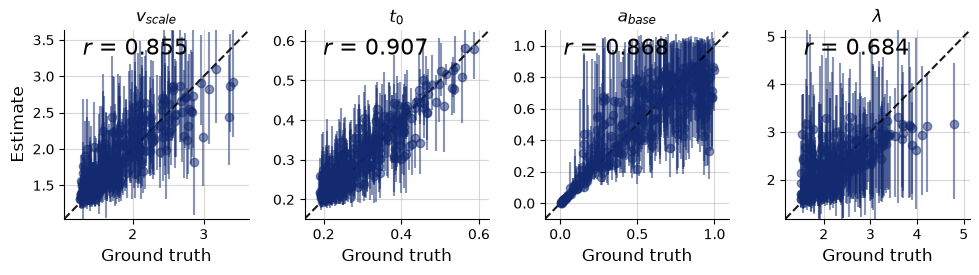

In [ ]:
f2 = bf.diagnostics.recovery(samples, test_sims, figsize = (10,3))

for ax in f2.axes:
    current_title = ax.get_title()
    new_title = label_map.get(current_title, current_title)  # fallback: Original, if Mapping fails
    ax.set_title(new_title, fontsize=12)
    ax.set_xlabel(ax.get_xlabel(), fontsize = 12)
    ax.set_ylabel(ax.get_ylabel(), fontsize = 12)
    ax.tick_params(axis='both', labelsize = 10)

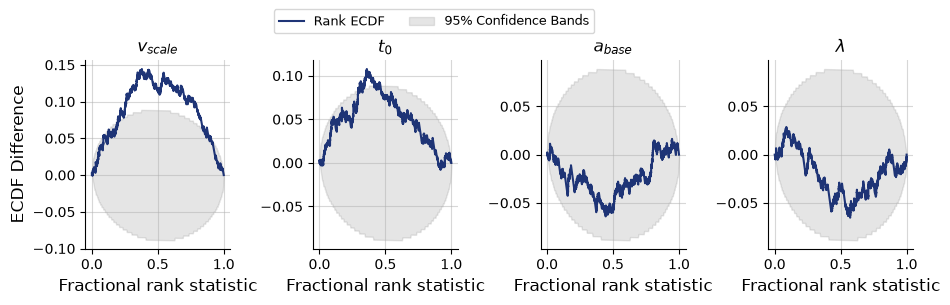

In [38]:
f3 = bf.diagnostics.calibration_ecdf(samples, test_sims, figsize=(10, 3))
for ax in f3.axes:
    current_title = ax.get_title()
    new_title = label_map.get(current_title, current_title)  # fallback: Original, if Mapping fails
    ax.set_title(new_title, fontsize=12)
    ax.set_xlabel(ax.get_xlabel(), fontsize = 12)
    ax.set_ylabel(ax.get_ylabel(), fontsize = 12)
    ax.tick_params(axis='both', labelsize = 10)

    legend = ax.get_legend()
    if legend is not None:
        legend.remove()

# Eine gemeinsame Legende fürs gesamte Figure holen
handles, labels = f3.axes[0].get_legend_handles_labels()
f3.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 1.05), ncol=len(labels), fontsize=9)

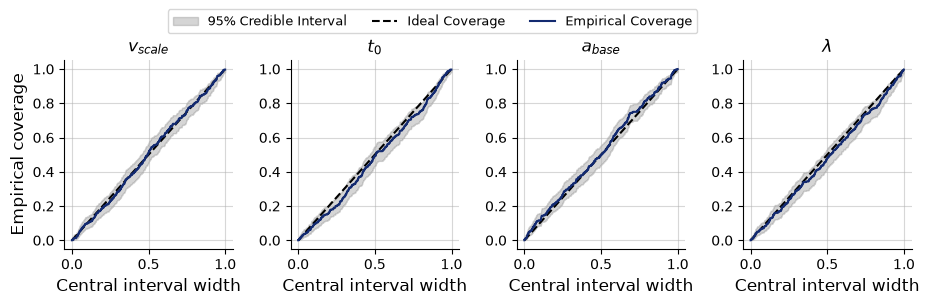

In [40]:
f4 = bf.diagnostics.coverage(samples, test_sims, figsize=(10, 3))
for ax in f4.axes:
    current_title = ax.get_title()
    new_title = label_map.get(current_title, current_title)  # fallback: Original, if Mapping fails
    ax.set_title(new_title, fontsize=12)
    ax.set_xlabel(ax.get_xlabel(), fontsize = 12)
    ax.set_ylabel(ax.get_ylabel(), fontsize = 12)
    ax.tick_params(axis='both', labelsize = 10)
    legend = ax.get_legend()
    if legend is not None:
        legend.remove()

# Eine gemeinsame Legende fürs gesamte Figure holen
handles, labels = f4.axes[0].get_legend_handles_labels()
f4.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 1.05), ncol=len(labels), fontsize=9)


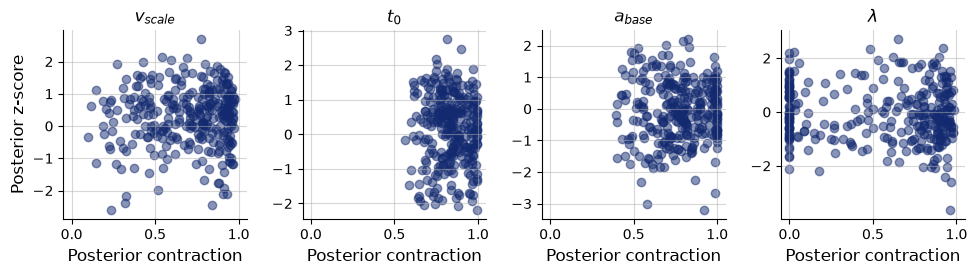

In [42]:
f5 = bf.diagnostics.z_score_contraction(samples, test_sims, figsize=(10, 3))

for ax in f5.axes:
    current_title = ax.get_title()
    new_title = label_map.get(current_title, current_title)  # fallback: Original, if Mapping fails
    ax.set_title(new_title, fontsize=12)
    ax.set_xlabel(ax.get_xlabel(), fontsize = 12)
    ax.set_ylabel(ax.get_ylabel(), fontsize = 12)
    ax.tick_params(axis='both', labelsize = 10)


## **Inference**

In [ ]:
empirical_data = pd.read_csv("./data/Katsimposis/experiment-2-Flash.csv")

# mapping
mapping_diff = {
    "[0.55, 0.45]": 0.1,
    "[0.6, 0.4]": 0.2,
    "[0.65, 0.35]": 0.3,
    "[0.7, 0.3]": 0.4,
    "[0.75,0.25]": 0.5,
    "[0.8,0.2]": 0.6
}
empirical_data['difficulty'] = empirical_data["difficulty"].replace(mapping_diff)

mapping_deadline = {
    "Deadline": 1,
    "No Deadline": 0
}
empirical_data["has_deadline"] = empirical_data["deadline"].replace(mapping_deadline)
empirical_data["deadline"] = empirical_data["deadline"].replace(mapping_deadline)

mapping_cue = {
    "AC":1,
    "SP":0
}
empirical_data["cue"] = empirical_data["cue"].replace(mapping_cue)


empirical_data = empirical_data[
    (empirical_data["cue"] == CUE) & (empirical_data["deadline"] == HAS_DEADLINE)
].reset_index(drop=True)
# print(empirical_data.shape, empirical_data["difficulty"].unique())

(4776, 8) [0.2 0.3 0.4 0.1]


In [75]:
df = empirical_data
# 1. Daten als reine 1D-NumPy-Arrays aus dem DataFrame extrahieren
# (Stelle sicher, dass 'choice', 'cue' und 'has_deadline' bereits reine Zahlen wie 0.0 oder 1.0 sind!)
rt_array = df['rt'].to_numpy(dtype=np.float64)
choice_array = df['acc'].to_numpy(dtype=np.float64)
coherence_array = df['difficulty'].to_numpy(dtype=np.float64)

# Für die Bedingungen (Conditions)
cue_array = df['cue'].to_numpy(dtype=np.float64)
deadline_array = df['has_deadline'].to_numpy(dtype=np.float64)

# 2. Batch-Dimension hinzufügen (Form von [Trials] zu [1, Trials] ändern)
# Das ist zwingend notwendig, da BayesFlow dreidimensionale Batches erwartet!
empirical_data_prep = {
    "rt": rt_array[np.newaxis, :],
    "choice": choice_array[np.newaxis, :],
    "coherence": coherence_array[np.newaxis, :],
    "cue": cue_array[np.newaxis, :],
    "has_deadline": deadline_array[np.newaxis, :]
}


In [76]:


# 1. Deine extrahierten 1D-Arrays aus dem DataFrame (wie gehabt)
rt_array = df['rt'].to_numpy(dtype=np.float64)
choice_array = df['acc'].to_numpy(dtype=np.float64)
coherence_array = df['difficulty'].to_numpy(dtype=np.float64)
cue_array = df['cue'].to_numpy(dtype=np.float64)
deadline_array = df['has_deadline'].to_numpy(dtype=np.float64)

# 2. Definiere eine verträgliche Chunk-Größe (z. B. 200 Trials pro Block)
# So bleibt die Attention-Matrix handhabbar (200x200 statt 19033x19033)
chunk_size = 400  
num_trials = len(rt_array)

all_samples = []

# Schleife über die Daten in kleinen Schritten
for i in range(0, num_trials, chunk_size):
    # Slice die Daten für den aktuellen Block
    rt_chunk = rt_array[i:i+chunk_size]
    choice_chunk = choice_array[i:i+chunk_size]
    coherence_chunk = coherence_array[i:i+chunk_size]
    cue_chunk = cue_array[i:i+chunk_size]
    deadline_chunk = deadline_array[i:i+chunk_size]
    
    # Überspringe den letzten Block, falls er winzig klein sein sollte
    if len(rt_chunk) < 10:
        continue
        
    # Baue das Mini-Batch-Dictionary mit führender Batch-Dimension (1, chunk_size)
    chunk_data = {
        "rt": rt_chunk[np.newaxis, :],
        "choice": choice_chunk[np.newaxis, :],
        "coherence": coherence_chunk[np.newaxis, :],
        "cue": cue_chunk[np.newaxis, :],
        "has_deadline": deadline_chunk[np.newaxis, :]
    }
    
    # Inferenz für diesen Chunk ausführen
    try:
        chunk_samples = approximator.sample(
            num_samples=1000, 
            conditions=chunk_data
        )
        # Extrahiere die geschätzten Parameter (passe den Key ggf. an deinen Output an)
        # Meistens liegen sie in 'parameters' oder direkt als Array im Dictionary
        if 'parameters' in chunk_samples:
            all_samples.append(chunk_samples['parameters'])
        else:
            # Falls BayesFlow das Ergebnis direkt flach ausgibt, nehmen wir den ersten Key
            first_key = list(chunk_samples.keys())[0]
            all_samples.append(chunk_samples[first_key])
            
    except Exception as e:
        # print(f"Fehler bei Chunk ab Index {i}: {e}")
        continue

# 3. Aggregation aller Chunks zu einem finalen Parameter-Set
# Wir mitteln die Posteriors über die verschiedenen Datenblöcke
if len(all_samples) > 0:
    all_samples = np.concatenate(all_samples, axis=0) # Form: (Anzahl_Chunks * 1000, Parameter_Dim)

# Der finale "beste" Parametervektor für die Katsimpokis-Daten:
final_parameter_estimates = np.mean(all_samples, axis=0)

print("Erfolgreich geschätzte Parameter-Mittelwerte:")
print(final_parameter_estimates)

Sampling: 100%|██████████| 1/1 [00:00<00:00,  4.83batch/s]

Erfolgreich geschätzte Parameter-Mittelwerte:
[[1.04653138]
 [1.08401618]
 [1.11193114]
 [1.11988894]
 [1.10859306]
 [1.06980736]
 [1.03898587]
 [1.09428791]
 [1.1155424 ]
 [1.09941059]
 [1.06059266]
 [1.06045443]
 [1.11343144]
 [1.03703272]
 [1.08838011]
 [1.12831778]
 [1.04873555]
 [1.06215446]
 [1.10277806]
 [1.08355913]
 [1.13115555]
 [1.09905032]
 [1.05706578]
 [1.07240512]
 [1.10069912]
 [1.05686752]
 [1.03022327]
 [1.1133993 ]
 [1.09392796]
 [1.05861419]
 [1.06257004]
 [0.99936981]
 [1.09481914]
 [1.02043541]
 [1.084998  ]
 [1.04407061]
 [1.10279922]
 [1.119151  ]
 [1.05587122]
 [1.06168404]
 [1.04502187]
 [1.11994731]
 [1.05499252]
 [1.07032001]
 [1.09198629]
 [1.08395532]
 [1.07981519]
 [1.06517864]
 [1.07346189]
 [1.14624943]
 [1.10053387]
 [1.00779213]
 [1.07967314]
 [1.11025364]
 [1.14261437]
 [1.09054935]
 [1.05109361]
 [1.13132163]
 [1.05382713]
 [1.12905855]
 [1.0759397 ]
 [1.07295632]
 [1.09696615]
 [1.09462165]
 [1.11320304]
 [1.13201884]
 [1.05466304]
 [1.12567121]
 [

In [77]:
resim_datasets = resimulate_from_posterior(all_samples, model="exponential", n_resim=100)

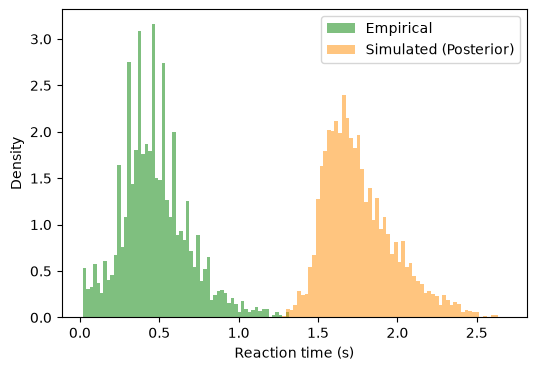

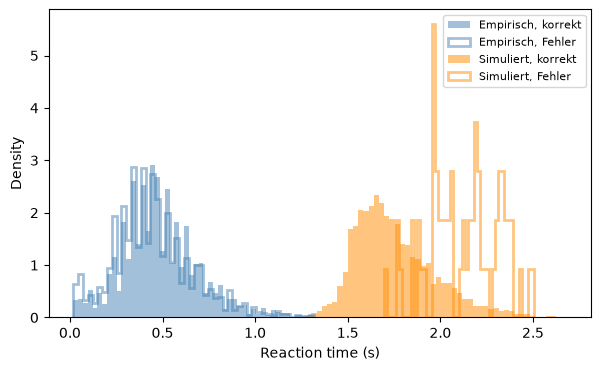

Empirische Accuracy: 0.6298157453936348
Simulierte Accuracy (Posterior-Mittel): 0.9845938


In [78]:
if len(resim_datasets) > 0:
    # 1. Alle Resim-RTs/Choices/Accuracy zusammenführen (nur gültige Antworten, choice != -1)
    resim_rt_all = np.concatenate([d["rt"][d["choice"] != -1] for d in resim_datasets])
    resim_choice_all = np.concatenate([d["choice"][d["choice"] != -1] for d in resim_datasets])

    # 2. Empirische Daten (bereits gefiltert auf CUE=0, HAS_DEADLINE=1)
    emp_rt = df["rt"].to_numpy(dtype=np.float64)
    emp_choice = df["acc"].to_numpy(dtype=np.float64)
    valid_emp = ~np.isnan(emp_choice)
    emp_rt, emp_choice = emp_rt[valid_emp], emp_choice[valid_emp]

    # 3a. RT-Verteilung insgesamt
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.hist(emp_rt, bins=60, density=True, alpha=0.5, label="Empirical", color="green")
    ax.hist(resim_rt_all, bins=60, density=True, alpha=0.5, label="Simulated (Posterior)", color="darkorange")
    ax.set_xlabel("Reaction time (s)"); ax.set_ylabel("Density")
    ax.legend()
    plt.show()

    # 3b. Getrennt nach korrekt/inkorrekt (Slow-Errors-Signatur etc.)
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.hist(emp_rt[emp_choice == 1], bins=50, density=True, alpha=0.5, label="Empirisch, korrekt", color="steelblue")
    ax.hist(emp_rt[emp_choice == 0], bins=50, density=True, alpha=0.5, label="Empirisch, Fehler", color="steelblue", histtype="step", linewidth=2)
    ax.hist(resim_rt_all[resim_choice_all == 1], bins=50, density=True, alpha=0.5, label="Simuliert, korrekt", color="darkorange")
    ax.hist(resim_rt_all[resim_choice_all == 0], bins=50, density=True, alpha=0.5, label="Simuliert, Fehler", color="darkorange", histtype="step", linewidth=2)
    ax.set_xlabel("Reaction time (s)"); ax.set_ylabel("Density")
    ax.legend(fontsize=8)
    plt.show()

    # 3c. Accuracy insgesamt (Anteil choice==1) empirisch vs. simuliert
    print("Empirische Accuracy:", emp_choice.mean())
    print("Simulierte Accuracy (Posterior-Mittel):", resim_choice_all.mean())

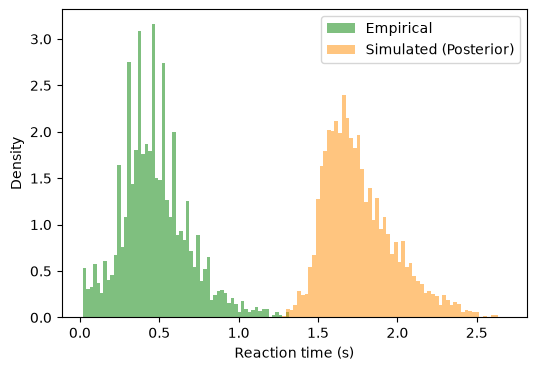

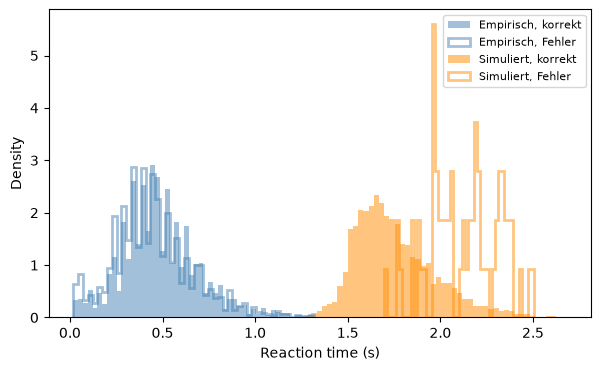

Empirische Accuracy: 0.6298157453936348
Simulierte Accuracy (Posterior-Mittel): 0.9845938


In [79]:
if len(resim_datasets) > 0:
    # 1. Alle Resim-RTs/Choices/Accuracy zusammenführen (nur gültige Antworten, choice != -1)
    resim_rt_all = np.concatenate([d["rt"][d["choice"] != -1] for d in resim_datasets])
    resim_choice_all = np.concatenate([d["choice"][d["choice"] != -1] for d in resim_datasets])

    # 2. Empirische Daten (bereits gefiltert auf CUE=0, HAS_DEADLINE=1)
    emp_rt = df["rt"].to_numpy(dtype=np.float64)
    emp_choice = df["acc"].to_numpy(dtype=np.float64)
    valid_emp = ~np.isnan(emp_choice)
    emp_rt, emp_choice = emp_rt[valid_emp], emp_choice[valid_emp]

    # 3a. RT-Verteilung insgesamt
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.hist(emp_rt, bins=60, density=True, alpha=0.5, label="Empirical", color="green")
    ax.hist(resim_rt_all, bins=60, density=True, alpha=0.5, label="Simulated (Posterior)", color="darkorange")
    ax.set_xlabel("Reaction time (s)"); ax.set_ylabel("Density")
    ax.legend()
    plt.show()

    # 3b. Getrennt nach korrekt/inkorrekt (Slow-Errors-Signatur etc.)
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.hist(emp_rt[emp_choice == 1], bins=50, density=True, alpha=0.5, label="Empirisch, korrekt", color="steelblue")
    ax.hist(emp_rt[emp_choice == 0], bins=50, density=True, alpha=0.5, label="Empirisch, Fehler", color="steelblue", histtype="step", linewidth=2)
    ax.hist(resim_rt_all[resim_choice_all == 1], bins=50, density=True, alpha=0.5, label="Simuliert, korrekt", color="darkorange")
    ax.hist(resim_rt_all[resim_choice_all == 0], bins=50, density=True, alpha=0.5, label="Simuliert, Fehler", color="darkorange", histtype="step", linewidth=2)
    ax.set_xlabel("Reaction time (s)"); ax.set_ylabel("Density")
    ax.legend(fontsize=8)
    plt.show()

    # 3c. Accuracy insgesamt (Anteil choice==1) empirisch vs. simuliert
    print("Empirische Accuracy:", emp_choice.mean())
    print("Simulierte Accuracy (Posterior-Mittel):", resim_choice_all.mean())